# Homework 6: Tree-Based Methods and SMOTE

## 1. Tree-Based Methods

### 1(a). Loading the APS Failure Data

The APS Failure at Scania Trucks dataset was downloaded from the UCI Machine Learning Repository. The task is to predict whether a truck failure is caused by the Air Pressure System (APS) (`pos`) or by another component (`neg`).

* The data comes as a separate training set and test set.
* Each row has **170 numeric features** (anonymized sensor readings) and one `class` column.
* Missing values are coded as `na` in the files and are read as `NaN`.
* The files begin with license text, so the loader finds the header row (the line starting with `class`) and skips everything above it.

In [1]:
import pandas as pd

train_path = "data/aps_failure_training_set.csv"
test_path = "data/aps_failure_test_set.csv"


def header_row(path):
    """Line number of the header row (the line starting with 'class')."""
    with open(path) as f:
        for i, line in enumerate(f):
            if line.startswith("class"):
                return i
    raise ValueError(f"No header row found in {path}")

df_train = pd.read_csv(train_path, skiprows=header_row(train_path),
                       na_values="na")
df_test = pd.read_csv(test_path, skiprows=header_row(test_path),
                      na_values="na")

assert df_train.shape == (60000, 171), df_train.shape
assert df_test.shape[1] == 171, df_test.shape

print("=" * 60)
print("1(a): APS FAILURE DATASET")
print("=" * 60)
for name, df in [("Training set", df_train), ("Test set", df_test)]:
    counts = df["class"].value_counts()
    n = len(df)
    missing = df.drop(columns="class").isna().mean().mean() * 100
    print(f"{name}: {n:,} rows x {df.shape[1]} columns "
          f"(170 features + class)")
    print(f"  neg: {counts['neg']:6,} ({counts['neg'] / n:6.2%})")
    print(f"  pos: {counts['pos']:6,} ({counts['pos'] / n:6.2%})")
    print(f"  Missing feature values: {missing:.2f}%")
    print("-" * 60)

1(a): APS FAILURE DATASET
Training set: 60,000 rows x 171 columns (170 features + class)
  neg: 59,000 (98.33%)
  pos:  1,000 ( 1.67%)
  Missing feature values: 8.33%
------------------------------------------------------------
Test set: 16,000 rows x 171 columns (170 features + class)
  neg: 15,625 (97.66%)
  pos:    375 ( 2.34%)
  Missing feature values: 8.41%
------------------------------------------------------------


**Result (1(a)):**

| | Rows | Negative (`neg`) | Positive (`pos`) | Missing feature values |
|---|---|---|---|---|
| Training set | 60,000 | 59,000 (98.33%) | 1,000 (1.67%) | 8.33% |
| Test set | 16,000 | 15,625 (97.66%) | 375 (2.34%) | 8.41% |

Both sets have 171 columns (170 features + `class`), matching the data description. The positive class (APS failures) is rare in both sets, which we examine further in 1(b)v. About 8.3% of all feature values are missing in each set, so missing data must be handled before modeling (1(b)i).

### 1(b). Data Preparation
### 1(b)i. Handling Missing Values

About 8.3% of all feature values are missing (1(a)), spread over many rows, so dropping rows with missing values would throw away a large share of the data. Common **data imputation** techniques are:

* **Mean / median / mode imputation:** replace each missing value with the feature's mean, median, or most frequent value. Simple and fast; the median is robust to skewed features and outliers.
* **Constant or indicator imputation:** fill with a fixed value (e.g. 0 or -1) and optionally add a binary "was missing" indicator, so the model can learn from the missingness itself.
* **k-nearest-neighbors (KNN) imputation:** fill a missing value with the average of that feature among the k most similar rows.
* **Iterative / multivariate imputation (MICE):** model each feature with missing values as a function of the other features, and iterate until the imputed values stabilize.
* **Model-based imputation:** predict missing values with a regression or tree model (e.g. random-forest imputation).
* **Deletion:** listwise (drop rows) or dropping features with too many missing values; only reasonable when little data is lost.

**Chosen method: median imputation.** The features are sensor counts and histogram bins with highly skewed distributions, so the median is more representative than the mean, and it scales easily to 60,000 rows × 170 features. Following footnote 1, the **training set is imputed with training medians** and the **test set with test medians**, so no statistics are shared between the two sets.

In [2]:
import numpy as np
import pandas as pd

# Features and labels (pos = 1, neg = 0)
X_train_raw = df_train.drop(columns="class")
X_test_raw = df_test.drop(columns="class")
y_train = (df_train["class"] == "pos").astype(int).values
y_test = (df_test["class"] == "pos").astype(int).values

# Median imputation:
#   training set -> training medians
#   test set     -> test medians (footnote 1: no access to training data
#                   when filling in test values)
train_medians = X_train_raw.median()
test_medians = X_test_raw.median()

assert train_medians.notna().all() and test_medians.notna().all(), \
    "A feature is entirely missing, so its median is undefined"

X_train = X_train_raw.fillna(train_medians)
X_test = X_test_raw.fillna(test_medians)

# Missing values per feature, before imputation (training set)
miss = X_train_raw.isna().mean().sort_values(ascending=False)
print(f"Features with missing values: {(miss > 0).sum()} of {len(miss)}")
print(f"Features missing in more than 50% of rows: {(miss > 0.5).sum()}")
print("\nMost-missing features (training set):")
print((miss.head(10) * 100).round(1).rename("% missing").to_string())

assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
print(f"\nAfter imputation: X_train {X_train.shape}, X_test {X_test.shape}, "
      "no missing values")

Features with missing values: 169 of 170
Features missing in more than 50% of rows: 8

Most-missing features (training set):
br_000    82.1
bq_000    81.2
bp_000    79.6
bo_000    77.2
cr_000    77.2
ab_000    77.2
bn_000    73.3
bm_000    65.9
bl_000    45.5
bk_000    38.4

After imputation: X_train (60000, 170), X_test (16000, 170), no missing values


**Result (1(b)i):**

* **169 of the 170 features** have missing values in the training set, so dropping rows with any missing value would remove almost all of the data. This confirms that imputation, not deletion, is the right approach.
* **8 features are missing in more than half of the rows.** The worst are `br_000` (82.1%), `bq_000` (81.2%), `bp_000` (79.6%), and `bo_000`, `cr_000` and `ab_000` (77.2% each).
* After median imputation (training medians for the training set, test medians for the test set), neither set has any missing values: `X_train` is (60000, 170) and `X_test` is (16000, 170).

**Note on the heavily missing features:** for the 8 features that are more than 50% missing, median imputation fills most of each column with a single value, so these features carry less information after imputation. We keep all 170 features because 1(b)ii asks for the CV of every feature, and tree-based models can simply ignore uninformative features. Adding "was missing" indicator variables would be a possible improvement.

#### 1(b)ii. Coefficient of Variation 

In [3]:
# Sample mean (m) and sample standard deviation (s) of each feature,
# computed on the imputed training set
mean_train = X_train.mean()
std_train = X_train.std(ddof=1)

# CV = s / m; undefined when the mean is 0
cv_train = (std_train / mean_train).replace([np.inf, -np.inf], np.nan)

undefined = cv_train[cv_train.isna()].index.tolist()
constant = std_train[std_train == 0].index.tolist()

df_cv_summary = pd.DataFrame({
    "Mean (m)": mean_train,
    "Std Dev (s)": std_train,
    "CV": cv_train,
}).sort_values("CV", ascending=False)

print(f"CV computed for {cv_train.notna().sum()} of {len(cv_train)} "
      "features")
print(f"Features with mean 0 (CV undefined): {undefined or 'none'}")
print(f"Constant features (s = 0, so CV = 0): {constant or 'none'}")
print(f"CV range: {cv_train.min():.4f} to {cv_train.max():.4f}\n")

pd.set_option("display.max_rows", 200)
display(df_cv_summary.round(4))

CV computed for 170 of 170 features
Features with mean 0 (CV undefined): none
Constant features (s = 0, so CV = 0): ['cd_000']
CV range: 0.0000 to 244.8875



,Mean (m),Std Dev (s),CV
cf_000,1.431075e+05,3.504525e+07,244.8875
co_000,1.433300e+05,3.504525e+07,244.5074
ad_000,1.434383e+05,3.504525e+07,244.3228
cs_009,7.705097e+02,1.833278e+05,237.9306
dh_000,4.392641e+03,5.412441e+05,123.2161
dj_000,3.727130e+01,4.379166e+03,117.4942
ag_000,2.191577e+02,2.036364e+04,92.9178
as_000,1.254079e+02,1.095219e+04,87.3325
ay_009,1.149620e+03,9.741156e+04,84.7337
ak_000,9.076607e+02,7.299859e+04,80.4250


**Result (1(b)ii):** CV was computed for all 170 features (no feature has mean 0). CV ranges from **0** to **244.8875**; the full sorted table is shown above.

* **Highest CV:** `cf_000` (244.89), `co_000` (244.51), `ad_000` (244.32) and `cs_009` (237.93), followed by `dh_000` (123.22) and `dj_000` (117.49). These features are almost always small but have a few enormous values: `cf_000`, `co_000` and `ad_000` all have the same standard deviation (3.50 × 10⁷), which suggests a few extreme values (possibly sentinel or error codes) shared by the same trucks. CV is very sensitive to such outliers, so a high CV here mostly reflects extreme skew.
* **Lowest CV:** apart from `cd_000`, the lowest CVs belong to `br_000` (0.69), `bq_000` (0.72), `bp_000` (0.75), `bo_000`, `bn_000`, `bm_000`, `bl_000` and `bk_000` (up to 0.87). These are exactly the features with the most missing values in 1(b)i (38% to 82% missing). Median imputation filled most of each column with one value, which shrinks its spread, so their low CV is largely an artifact of imputation.
* **Constant feature:** `cd_000` has the same value (1,209,600) in every training row, so its standard deviation and CV are 0. It carries no information and cannot help any model.
* **Duplicate features:** `bu_000`, `bv_000` and `cq_000` have identical means and standard deviations (and therefore identical CVs of 2.4050), suggesting they are copies of the same measurement. We check this in the correlation matrix (1(b)iii).

#### 1(b)iii. Correlation Matrix

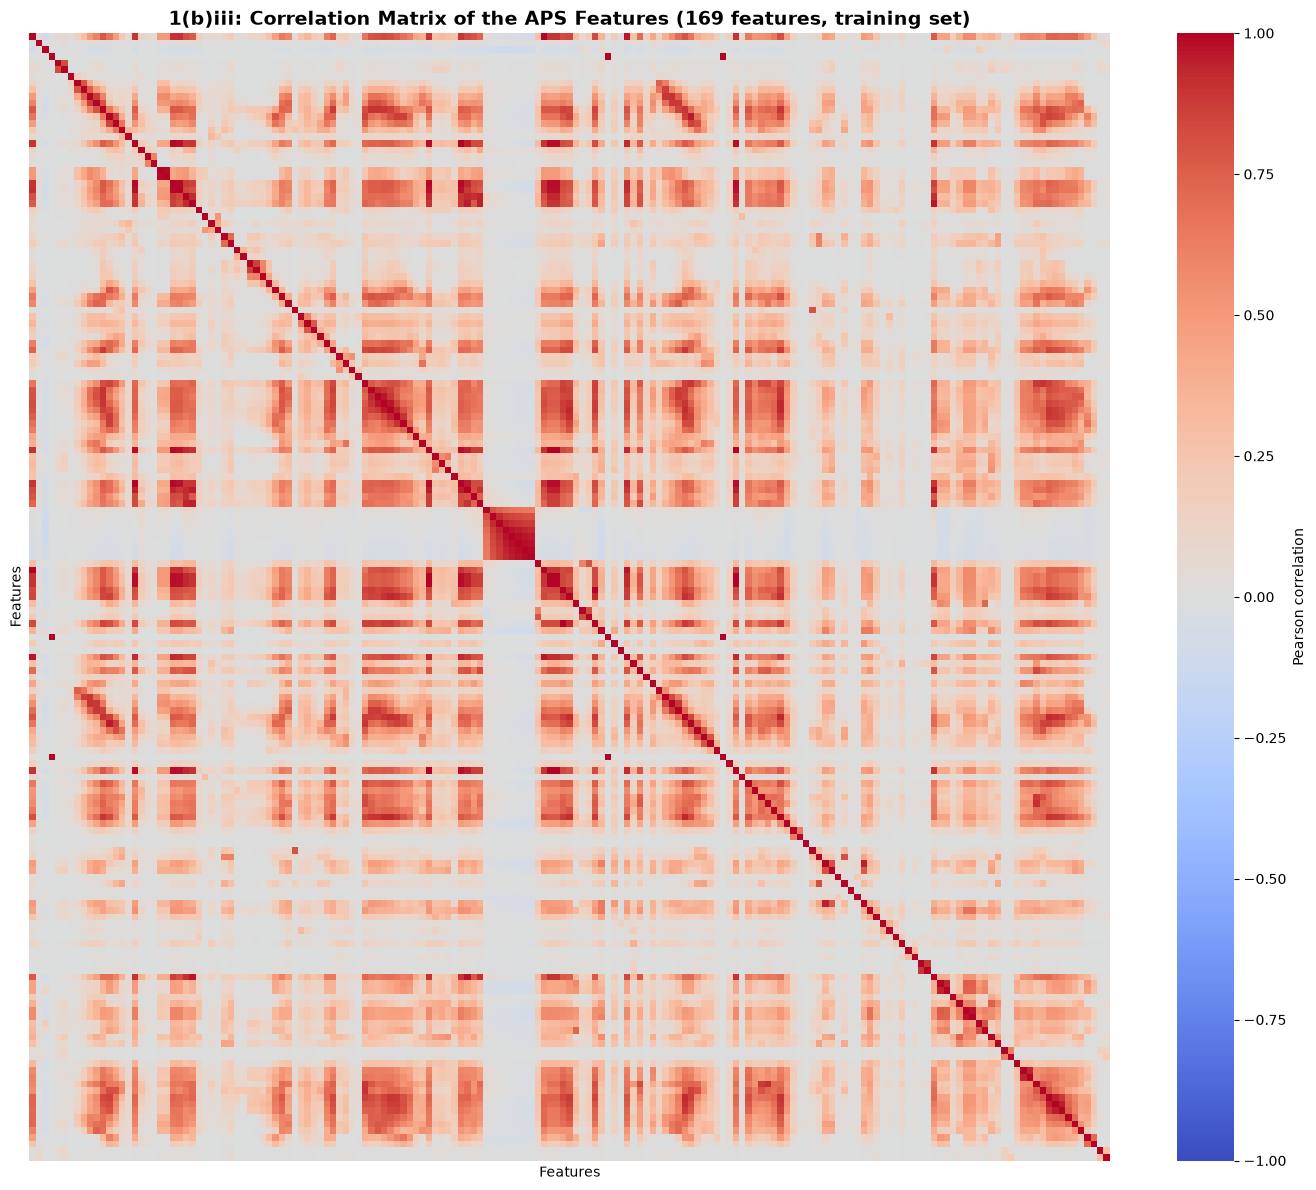

Feature pairs: 14,196
Pairs with |r| > 0.95: 55
Pairs with |r| > 0.80: 367

Ten most correlated feature pairs:
  bv_000   cq_000   r = 1.0000
  bu_000   cq_000   r = 1.0000
  bu_000   bv_000   r = 1.0000
  cf_000   co_000   r = 1.0000
  ad_000   cf_000   r = 1.0000
  ad_000   co_000   r = 1.0000
  aa_000   bt_000   r = 0.9988
  ah_000   bg_000   r = 0.9977
  bb_000   bv_000   r = 0.9963
  bb_000   bu_000   r = 0.9963

Suspected duplicates from 1(b)ii:
  bu_000 vs bv_000: r = 1.0000
  bu_000 vs cq_000: r = 1.0000
  bv_000 vs cq_000: r = 1.0000


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# cd_000 is constant (1(b)ii), so its correlations are undefined
corr_features = X_train.drop(columns=["cd_000"])
correlation_matrix = corr_features.corr()

plt.figure(figsize=(14, 12), dpi=100)
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,   # 169 names per axis would overlap
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)
plt.title("1(b)iii: Correlation Matrix of the APS Features "
          f"({correlation_matrix.shape[0]} features, training set)",
          fontsize=14, fontweight="bold")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# All feature pairs, strongest first
upper = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1))
pairs = upper.stack().dropna()
abs_pairs = pairs.abs().sort_values(ascending=False)

n_pairs = len(pairs)
print(f"Feature pairs: {n_pairs:,}")
print(f"Pairs with |r| > 0.95: {(abs_pairs > 0.95).sum()}")
print(f"Pairs with |r| > 0.80: {(abs_pairs > 0.80).sum()}")

print("\nTen most correlated feature pairs:")
for (f1, f2) in abs_pairs.index[:10]:
    print(f"  {f1:<8} {f2:<8} r = {pairs[(f1, f2)]:.4f}")

print("\nSuspected duplicates from 1(b)ii:")
for f1, f2 in [("bu_000", "bv_000"), ("bu_000", "cq_000"),
               ("bv_000", "cq_000")]:
    print(f"  {f1} vs {f2}: r = {correlation_matrix.loc[f1, f2]:.4f}")

**Result (1(b)iii):**

* **Strong, almost entirely positive correlations.** The heatmap is dominated by positive (red) correlations with almost no negative ones, as expected since the features are counts and histogram bins that grow together with how much a truck is used. Several blocks of highly correlated features are visible, including the large block near the center.
* **Many redundant features:** of the 14,196 feature pairs, **367 have |r| > 0.80** and **55 have |r| > 0.95**.
* **Duplicates and outlier-driven correlations:** `bu_000`, `bv_000` and `cq_000` are perfectly correlated (r = 1.0000) and have identical means and standard deviations (1(b)ii), so they appear to be true duplicates. `ad_000`, `cf_000` and `co_000` also show r = 1.0000, but the scatter plots in 1(b)iv show they are **not** duplicates: their correlation is driven by a single extreme value (about $10^9$) shared by all three. Pearson correlation is highly sensitive to such outliers. Other near-duplicates include `aa_000`/`bt_000` (r = 0.9988) and `ah_000`/`bg_000` (r = 0.9977).
* **Implications:** many features carry overlapping information. Tree-based models handle this well (a tree simply uses one of several redundant features), but it means the importance of any single feature should not be over-interpreted, and it is another reason the CV ranking in 1(b)iv cannot tell us which features are significant.

#### 1(b)iv. Scatter Plots and Box Plots of the Highest-CV Features 

Top 13 features by CV:
   1. cf_000   CV = 244.8875
   2. co_000   CV = 244.5074
   3. ad_000   CV = 244.3228
   4. cs_009   CV = 237.9306
   5. dh_000   CV = 123.2161
   6. dj_000   CV = 117.4942
   7. ag_000   CV = 92.9178
   8. as_000   CV = 87.3325
   9. ay_009   CV = 84.7337
  10. ak_000   CV = 80.4250
  11. az_009   CV = 77.8385
  12. ch_000   CV = 77.4539
  13. au_000   CV = 68.8828


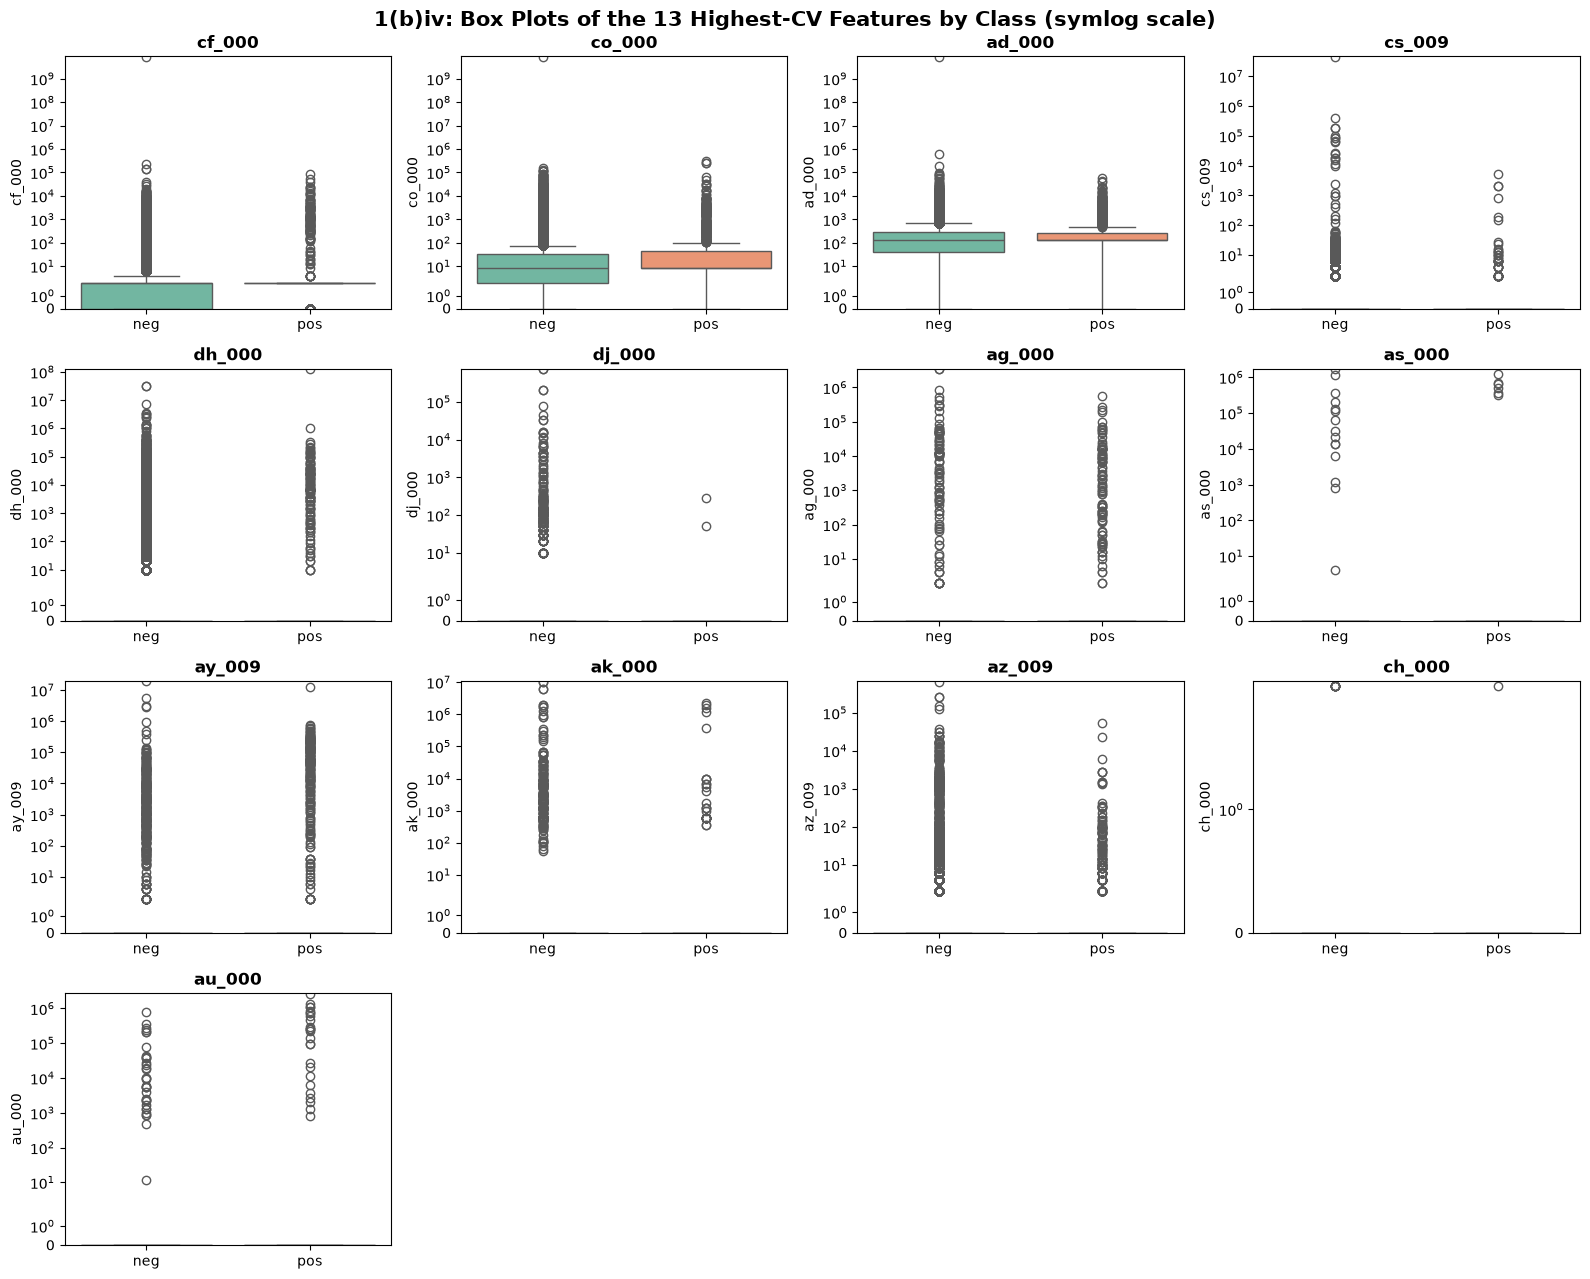

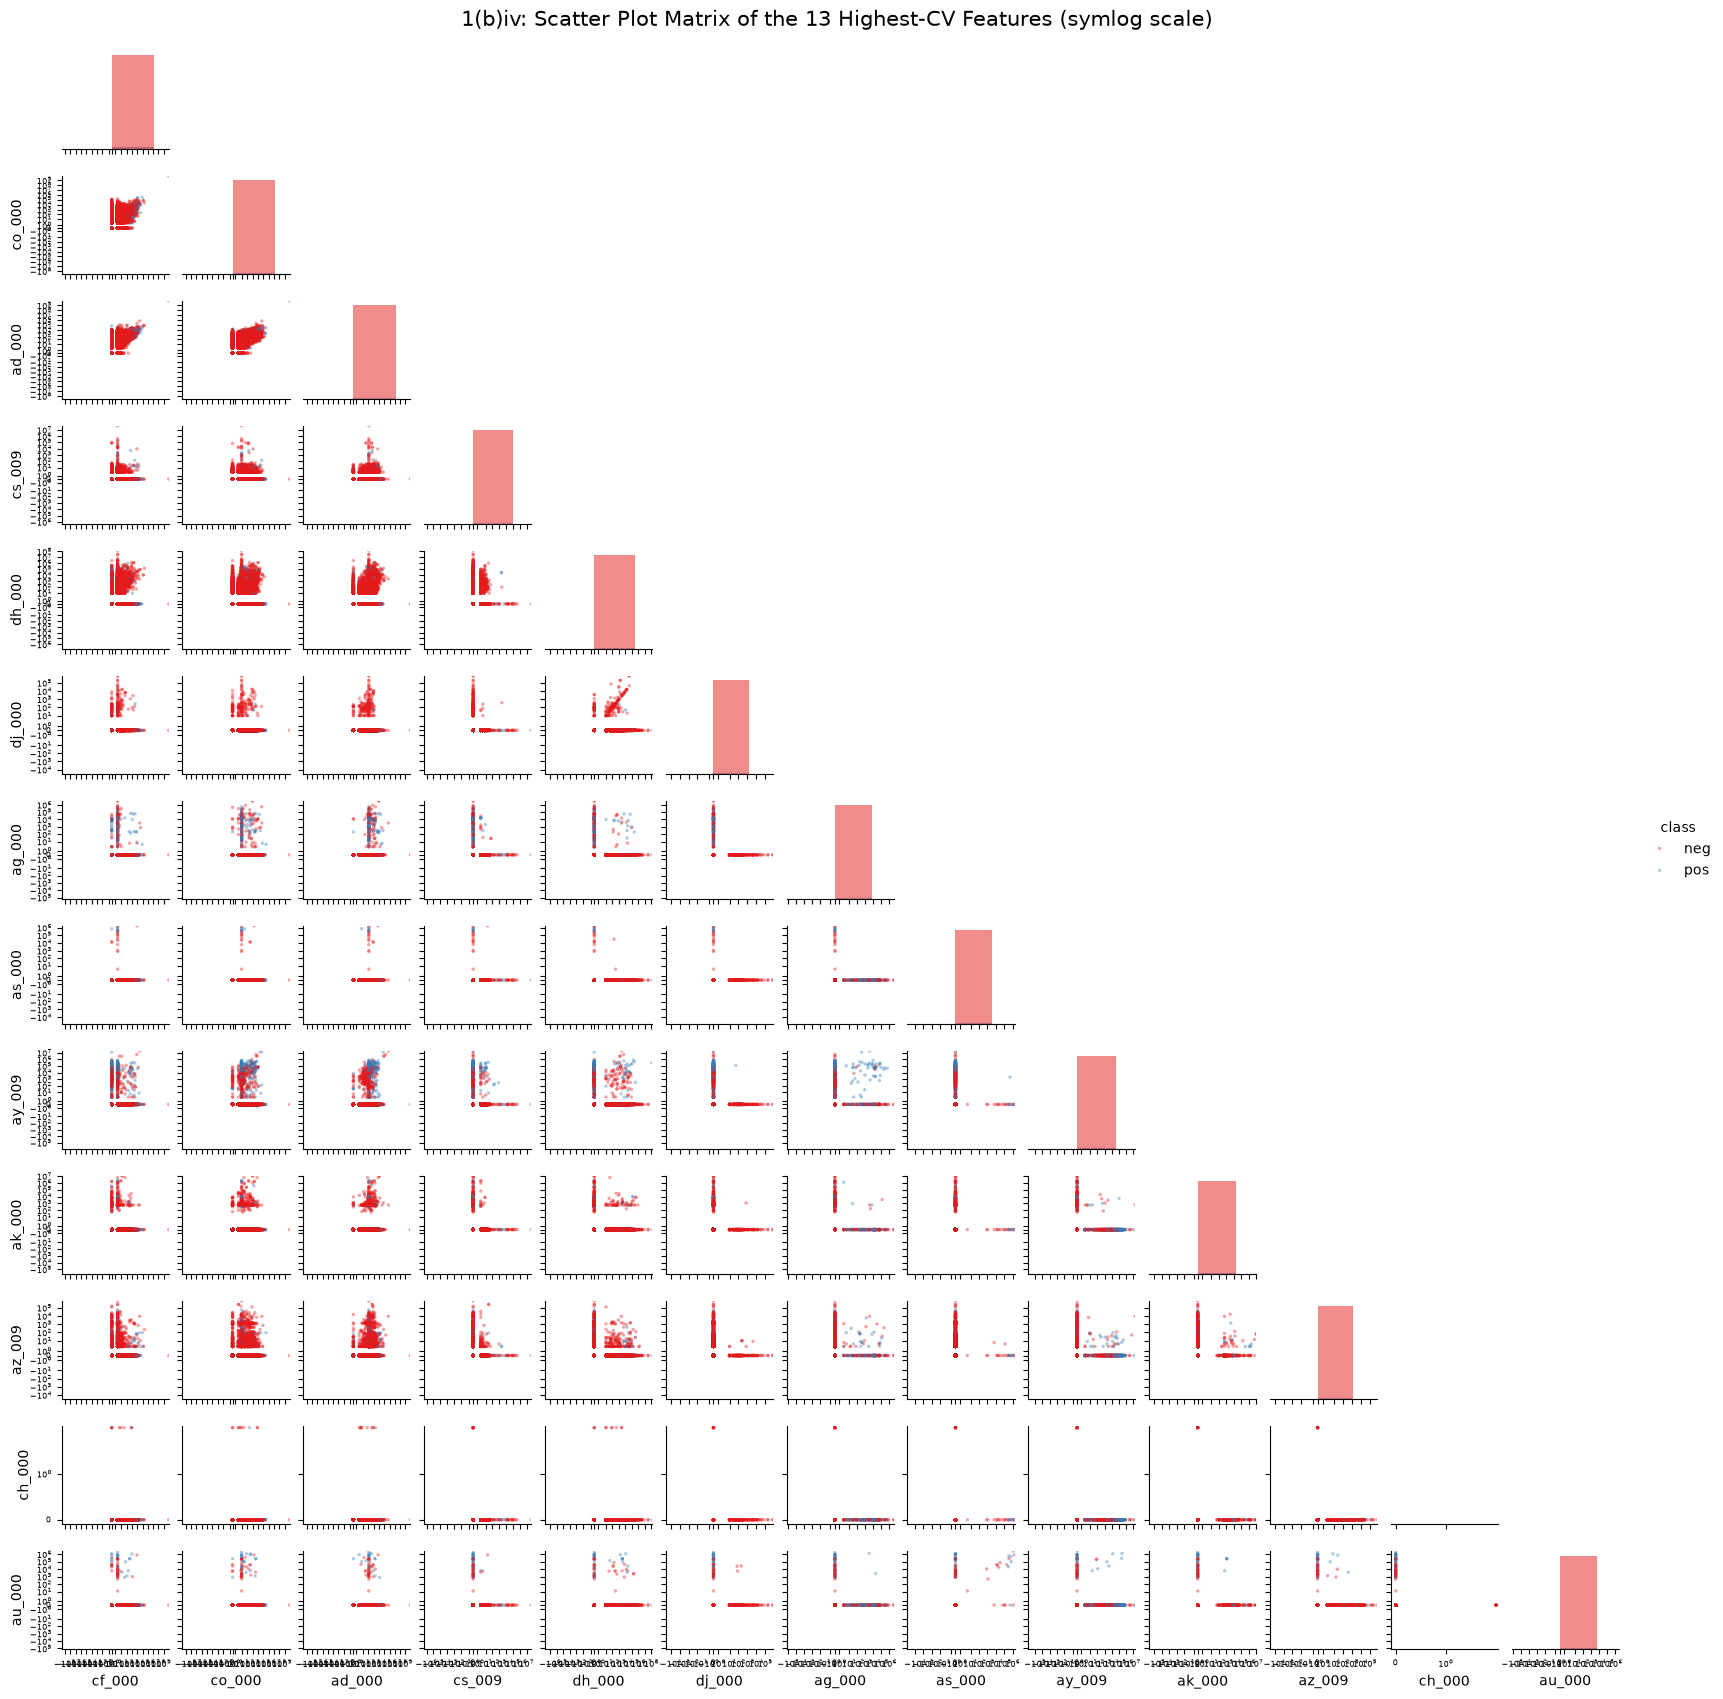

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. floor(sqrt(170)) = 13 features with the highest CV
num_features = int(np.floor(np.sqrt(170)))
top_features = cv_train.nlargest(num_features).index.tolist()

print(f"Top {num_features} features by CV:")
for i, f in enumerate(top_features, 1):
    print(f"  {i:2d}. {f:<8} CV = {cv_train[f]:.4f}")

df_visual = X_train[top_features].copy()
df_visual["class"] = np.where(y_train == 1, "pos", "neg")

# 2. Box plots by class (as on ISLR p. 129); symlog axis because of
#    extreme outliers
fig, axes = plt.subplots(4, 4, figsize=(16, 13), dpi=100)
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=df_visual, x="class", y=feature, hue="class",
                palette="Set2", legend=False, ax=ax)
    ax.set_yscale("symlog")
    ax.set_ylim(bottom=0) 
    ax.set_title(feature, fontweight="bold")
    ax.set_xlabel("")
for ax in axes.flat[num_features:]:
    ax.axis("off")
plt.suptitle("1(b)iv: Box Plots of the 13 Highest-CV Features by Class "
             "(symlog scale)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Scatter plot matrix of all 13 features, colored by class
g = sns.pairplot(df_visual, vars=top_features, hue="class",
                 hue_order=["neg", "pos"], palette="Set1",
                 corner=True, diag_kind="hist", height=1.3,
                 plot_kws={"alpha": 0.4, "s": 6, "linewidth": 0})
for ax in g.axes.flat:
    if ax is not None:
        ax.set_xscale("symlog")
        ax.set_yscale("symlog")
        ax.tick_params(labelsize=6)
g.figure.suptitle("1(b)iv: Scatter Plot Matrix of the 13 Highest-CV "
                  "Features (symlog scale)", y=1.01, fontsize=15)
plt.show()


**Result (1(b)iv):**

* **Box plots:** for 10 of the 13 features (`cs_009` through `au_000`), the median and quartiles are 0 in both classes, so the box collapses to a line at 0 and every nonzero value appears as an outlier. These features are zero for most trucks and very large for a few, which is why their CV is so high. Only `cf_000`, `co_000` and `ad_000` show a visible box, and the `neg` and `pos` boxes overlap heavily (`co_000` is slightly higher for `pos`).
* **Scatter plots:** in most panels the `pos` points lie inside the cloud of `neg` points, or along the axes where one of the features is 0. The clearest pattern is `ay_009`: `pos` trucks tend to have high `ay_009` values (e.g. against `co_000`, `ad_000` and `ag_000`), and a few `pos` trucks have high values of both `as_000` and `au_000`. No pair of features separates the classes cleanly.
* **Outlier-driven correlation:** the panels for `cf_000`, `co_000` and `ad_000` are clouds, not straight lines, so their r = 1.0000 in 1(b)iii comes from the single extreme value they share, not from the features being identical.

**Can we draw conclusions about the significance of these features just from the scatter plots? No.**

* A high CV only means a feature's spread is large relative to its mean; here it mostly reflects extreme skew and outliers, not a relationship with the class.
* The plots show features one or two at a time and ignore the other 157 features, many of which are strongly correlated with these (1(b)iii). A feature that looks uninformative alone may matter in combination with others, and vice versa.
* The classes are very imbalanced (1,000 `pos` vs 59,000 `neg`), so `pos` points are easily hidden behind `neg` points, and patterns like the one in `ay_009` rest on relatively few trucks.
* Plots give no standard errors or p-values. Judging significance requires a fitted model and a test, or a model-based measure such as feature importance from the random forest in 1(c).

#### 1(b)v. Class Balance

We count the positive (APS failure) and negative instances in the training and test sets.

In [6]:
import numpy as np

print("=" * 60)
print("1(b)v: CLASS DISTRIBUTION")
print("=" * 60)

for name, y in [("Training set", y_train), ("Test set", y_test)]:
    n_neg, n_pos = np.bincount(y)
    n = len(y)
    print(f"{name} ({n:,} rows)")
    print(f"  neg (0): {n_neg:6,} ({n_neg / n:6.2%})")
    print(f"  pos (1): {n_pos:6,} ({n_pos / n:6.2%})")
    print(f"  Imbalance ratio (neg : pos): {n_neg / n_pos:.1f} : 1")
    print("-" * 60)

# Accuracy of a model that always predicts 'neg'
print(f"Always predicting 'neg' would give accuracy "
      f"{1 - y_train.mean():.2%} (train) and {1 - y_test.mean():.2%} (test).")

1(b)v: CLASS DISTRIBUTION
Training set (60,000 rows)
  neg (0): 59,000 (98.33%)
  pos (1):  1,000 ( 1.67%)
  Imbalance ratio (neg : pos): 59.0 : 1
------------------------------------------------------------
Test set (16,000 rows)
  neg (0): 15,625 (97.66%)
  pos (1):    375 ( 2.34%)
  Imbalance ratio (neg : pos): 41.7 : 1
------------------------------------------------------------
Always predicting 'neg' would give accuracy 98.33% (train) and 97.66% (test).


**Result (1(b)v):**

| | Negative (`neg`) | Positive (`pos`) | Ratio (neg : pos) |
|---|---|---|---|
| Training set | 59,000 (98.33%) | 1,000 (1.67%) | 59.0 : 1 |
| Test set | 15,625 (97.66%) | 375 (2.34%) | 41.7 : 1 |

**Yes, the data set is highly imbalanced.** Only 1.67% of the training instances are positive, about 1 positive for every 59 negatives. A classifier that always predicts `neg` would already reach **98.33%** training accuracy (**97.66%** on the test set) while detecting no failures at all, so accuracy alone is a misleading measure here. For this reason we also report the confusion matrix, ROC and AUC in 1(c) to 1(f), and in 1(d) and 1(f) we compensate for the imbalance.

### 1(c). Random Forest (No Class Imbalance Compensation)

We train a random forest (100 trees) on the imputed training set with no adjustment for the class imbalance. For both the training and test sets we report the confusion matrix, misclassification rate, ROC curve and AUC, plus recall and precision for the positive class, since accuracy alone is misleading with a 59:1 imbalance (1(b)v). We also compute the out-of-bag (OOB) error estimate and compare it with the test error.

1(c): RANDOM FOREST (NO CLASS IMBALANCE COMPENSATION)
--- Train set ---


,Pred neg,Pred pos
Actual neg,59000,0
Actual pos,1,999


  misclassification  0.00002
  AUC                1.00000
  recall (pos)       0.99900
  precision (pos)    1.00000

--- Test set ---


,Pred neg,Pred pos
Actual neg,15610,15
Actual pos,106,269


  misclassification  0.00756
  AUC                0.99277
  recall (pos)       0.71733
  precision (pos)    0.94718



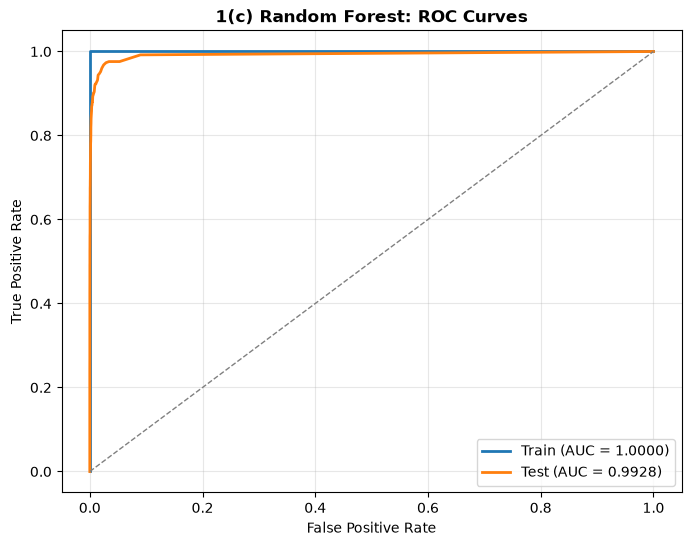

Out-of-bag (OOB) error estimate: 0.00612
Test misclassification rate:     0.00756


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_curve, auc,
                             recall_score, precision_score)


def evaluate_classifier(model, title):
    """Confusion matrix, misclassification, recall/precision for pos,
    ROC and AUC on the training and test sets."""
    results = {}
    plt.figure(figsize=(8, 6), dpi=100)
    for name, X, y in [("Train", X_train, y_train),
                       ("Test", X_test, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, pred)
        fpr, tpr, _ = roc_curve(y, prob)
        res = {"misclassification": np.mean(pred != y),
               "AUC": auc(fpr, tpr),
               "recall (pos)": recall_score(y, pred),
               "precision (pos)": precision_score(y, pred,
                                                  zero_division=0)}
        results[name] = res

        print(f"--- {name} set ---")
        display(pd.DataFrame(cm, index=["Actual neg", "Actual pos"],
                             columns=["Pred neg", "Pred pos"]))
        for k, v in res.items():
            print(f"  {k:<18} {v:.5f}")
        print()
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {res['AUC']:.4f})")

    plt.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title}: ROC Curves", fontweight="bold")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()
    return results


# Random forest with no compensation for class imbalance
rf_model = RandomForestClassifier(n_estimators=100, oob_score=True,
                                  random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

print("=" * 60)
print("1(c): RANDOM FOREST (NO CLASS IMBALANCE COMPENSATION)")
print("=" * 60)
rf_results = evaluate_classifier(rf_model, "1(c) Random Forest")

oob_error = 1 - rf_model.oob_score_
print(f"Out-of-bag (OOB) error estimate: {oob_error:.5f}")
print(f"Test misclassification rate:     "
      f"{rf_results['Test']['misclassification']:.5f}")

**Result (1(c)):**

| | Misclassification | AUC | Recall (pos) | Precision (pos) |
|---|---|---|---|---|
| Training set | 0.00002 | 1.00000 | 0.99900 | 1.00000 |
| Test set | **0.00756** | **0.99277** | **0.71733** | 0.94718 |

**Out-of-bag error estimate: 0.00612** (test misclassification 0.00756).

* **Training set:** almost perfect (1 error out of 60,000, AUC = 1.0). This is expected: each tree is grown deep on its bootstrap sample, so the forest nearly memorizes the training data. Training error is therefore not a useful measure of performance; the OOB and test errors are.
* **Test set:** 121 of 16,000 trucks are misclassified (0.756%), and the test AUC is high (0.9928), so the forest ranks trucks by failure risk very well. For comparison, always predicting `neg` would give a test error of 2.34% (1(b)v).
* **The errors fall mostly on the rare class.** Only 15 of 15,625 negative trucks are misclassified, but **106 of the 375 APS failures are missed**, so recall for `pos` is only 0.717. With 59 negatives for every positive in training, the trees' majority votes favor `neg`, and the default 0.5 threshold misses more than a quarter of the failures. In this application a missed failure is the costly error, so this is the main weakness of the uncompensated model.
* **OOB vs. test error:** the OOB estimate (0.00612) is slightly lower than the test error (0.00756). OOB error is computed on the training data, which has a smaller share of positives (1.67%) than the test set (2.34%); since most errors are on positives, a set with more positives has a higher error rate. Taking this into account, the OOB estimate is a reasonable approximation of the test error, and it comes for free, without a separate validation set.

### 1(d). Random Forest with Class Imbalance Compensation

Common ways to address class imbalance in random forests are:

* **Class weighting (cost-sensitive learning):** give errors on the minority class a larger weight when growing the trees, so splits that separate the rare class count more. In scikit-learn, `class_weight="balanced"` weights each class inversely to its frequency, and `class_weight="balanced_subsample"` recomputes those weights within each tree's bootstrap sample.
* **Balanced random forest (resampling per tree):** draw each tree's bootstrap sample so that both classes are equally represented, by undersampling the majority class or oversampling the minority class.
* **Resampling the training set:** undersample the majority class, or oversample the minority class (e.g. SMOTE, which we use in 1(f)), before training.
* **Adjusting the decision threshold:** predict `pos` when its predicted probability exceeds a threshold lower than 0.5.

We try two of these methods and repeat every output of 1(c) for each: **class weighting** (`RandomForestClassifier` with `class_weight="balanced_subsample"`) and a **balanced random forest** (`BalancedRandomForestClassifier` from `imbalanced-learn`), in which each tree is trained on a sample where the negative class is randomly undersampled to the size of the positive class.

#### Method 1: Class weighting


1(d): RANDOM FOREST WITH CLASS WEIGHTS
--- Train set ---


,Pred neg,Pred pos
Actual neg,59000,0
Actual pos,1,999


  misclassification  0.00002
  AUC                1.00000
  recall (pos)       0.99900
  precision (pos)    1.00000

--- Test set ---


,Pred neg,Pred pos
Actual neg,15608,17
Actual pos,158,217


  misclassification  0.01094
  AUC                0.98916
  recall (pos)       0.57867
  precision (pos)    0.92735



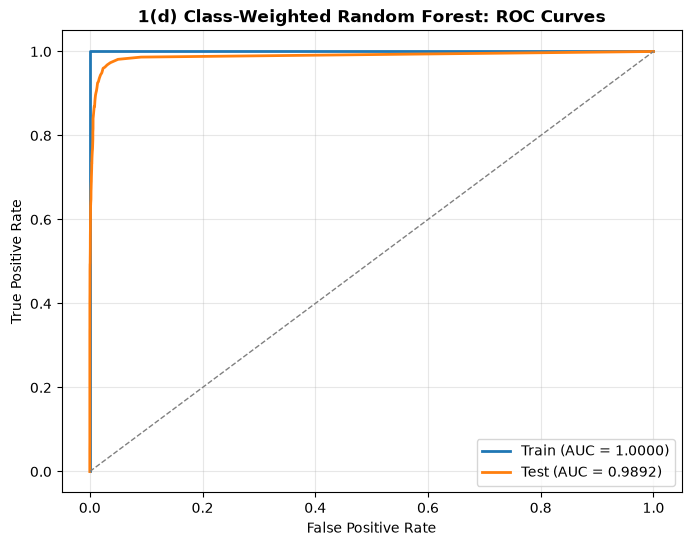

Out-of-bag (OOB) error estimate: 0.00803
Test misclassification rate:     0.01094


In [8]:
# Random forest with class weights inversely proportional to class
# frequency, recomputed within each tree's bootstrap sample
rf_balanced = RandomForestClassifier(n_estimators=100, oob_score=True,
                                     class_weight="balanced_subsample",
                                     random_state=42, n_jobs=-1)
rf_balanced.fit(X_train, y_train)

print("=" * 60)
print("1(d): RANDOM FOREST WITH CLASS WEIGHTS")
print("=" * 60)
rf_bal_results = evaluate_classifier(rf_balanced,
                                     "1(d) Class-Weighted Random Forest")

oob_error_bal = 1 - rf_balanced.oob_score_
print(f"Out-of-bag (OOB) error estimate: {oob_error_bal:.5f}")
print(f"Test misclassification rate:     "
      f"{rf_bal_results['Test']['misclassification']:.5f}")


**Result (Method 1, class weighting):** test misclassification **0.01094**, test AUC **0.98916**, recall (pos) **0.57867**, precision (pos) **0.92735**; OOB error **0.00803**. The model misses **158 of the 375** test failures, more than the uncompensated forest in 1(c) (106). The training results are identical to 1(c) (1 error out of 60,000), so the class weights did not change how well the forest fits the training data, only which splits it chose. See the comparison below.

#### Method 2: Balanced random forest (undersampling per tree)

1(d): BALANCED RANDOM FOREST (UNDERSAMPLING PER TREE)
--- Train set ---


/opt/anaconda3/lib/python3.14/site-packages/imblearn/ensemble/_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,Pred neg,Pred pos
Actual neg,55762,3238
Actual pos,0,1000


  misclassification  0.05397
  AUC                0.99721
  recall (pos)       1.00000
  precision (pos)    0.23596

--- Test set ---


,Pred neg,Pred pos
Actual neg,14789,836
Actual pos,6,369


  misclassification  0.05262
  AUC                0.99202
  recall (pos)       0.98400
  precision (pos)    0.30622



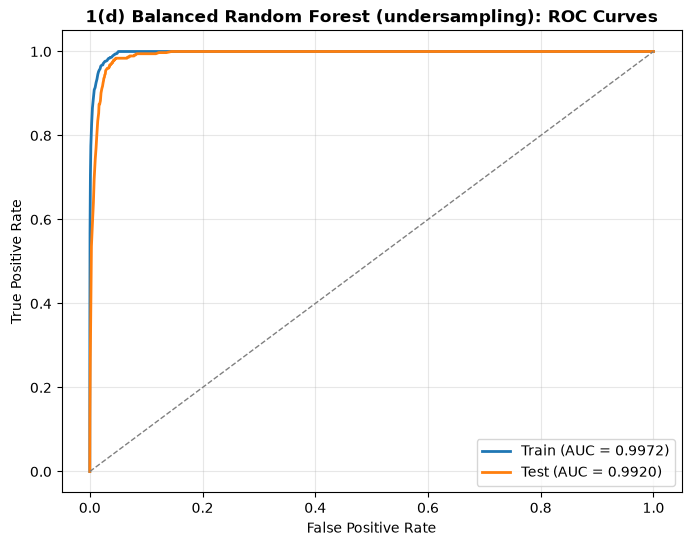

Out-of-bag (OOB) error estimate: 0.03285
Test misclassification rate:     0.05262

Comparison:


,Test misclassification,Test AUC,Test recall (pos),Test precision (pos),OOB error
Model,,,,,
1(c) uncompensated,0.00756,0.99277,0.71733,0.94718,0.00612
1(d) class weights,0.01094,0.98916,0.57867,0.92735,0.00803
1(d) undersampling per tree,0.05262,0.99202,0.98400,0.30622,0.03285


In [9]:
from imblearn.ensemble import BalancedRandomForestClassifier

# Each tree is trained on a sample where neg is undersampled to match pos
brf = BalancedRandomForestClassifier(n_estimators=100, oob_score=True,
                                     sampling_strategy="auto",
                                     replacement=False, bootstrap=True,
                                     random_state=42, n_jobs=-1)
brf.fit(X_train, y_train)

print("=" * 60)
print("1(d): BALANCED RANDOM FOREST (UNDERSAMPLING PER TREE)")
print("=" * 60)
brf_results = evaluate_classifier(brf, "1(d) Balanced Random Forest "
                                       "(undersampling)")

oob_error_brf = 1 - brf.oob_score_
print(f"Out-of-bag (OOB) error estimate: {oob_error_brf:.5f}")
print(f"Test misclassification rate:     "
      f"{brf_results['Test']['misclassification']:.5f}")

rows = []
for label, res, oob in [
        ("1(c) uncompensated", rf_results, oob_error),
        ("1(d) class weights", rf_bal_results, oob_error_bal),
        ("1(d) undersampling per tree", brf_results, oob_error_brf)]:
    rows.append({"Model": label,
                 "Test misclassification": res["Test"]["misclassification"],
                 "Test AUC": res["Test"]["AUC"],
                 "Test recall (pos)": res["Test"]["recall (pos)"],
                 "Test precision (pos)": res["Test"]["precision (pos)"],
                 "OOB error": oob})
print("\nComparison:")
display(pd.DataFrame(rows).set_index("Model").round(5))

**Result (1(d)):**

| Model | Test misclassification | Test AUC | Test recall (pos) | Test precision (pos) | OOB error |
|---|---|---|---|---|---|
| 1(c) uncompensated | 0.00756 | 0.99277 | 0.71733 | 0.94718 | 0.00612 |
| 1(d) class weights | 0.01094 | 0.98916 | 0.57867 | 0.92735 | 0.00803 |
| 1(d) undersampling per tree | 0.05262 | 0.99202 | **0.98400** | 0.30622 | 0.03285 |

* **Class weighting did not help.** Test recall for `pos` *fell* from 0.717 to 0.579 (158 missed failures instead of 106), and every other metric got slightly worse. Because the trees are grown until every leaf is pure, the class weights cannot change any leaf's prediction; they only change which splits are chosen, pushing the trees to isolate individual training positives in small leaves. These fit the training data perfectly but generalize worse.
* **Undersampling per tree works.** The balanced random forest misses only **6 of the 375 failures** (recall 0.984, versus 0.717 in 1(c)). Each tree sees as many failures as non-failures, so its votes are no longer dominated by the majority class.
* **The cost is false positives.** The balanced forest flags 836 of the 15,625 healthy trucks as failures (precision 0.306), so its overall misclassification rate rises from 0.00756 to 0.05262. This is the usual trade-off of compensating for imbalance: fewer missed positives in exchange for more false alarms.
* **AUC barely changes** (0.9928 vs. 0.9920): all three forests rank trucks by risk about equally well. Compensation mainly moves *where* the decision threshold falls on that ranking, trading precision for recall.
* **Training results:** unlike 1(c), the balanced forest no longer fits the training set perfectly (training misclassification 0.054), because each tree is trained on only about 2,000 trucks.
* **OOB vs. test error:** for the balanced forest, the OOB estimate (0.03285) understates the test error (0.05262), and scikit-learn warns that some training rows have no OOB prediction. With each tree trained on a small, rebalanced sample, the OOB estimate is less reliable than in 1(c).

**Which is better depends on the costs.** If a missed APS failure is much more expensive than an unnecessary inspection, which is typical for this problem, the balanced random forest is far preferable despite its higher overall error, since it catches almost every failure.

### 1(e). XGBoost with $L_1$ Penalty (No Class Imbalance Compensation)

We fit a gradient boosting tree classifier with XGBoost and an $L_1$ penalty $\alpha$ (`reg_alpha`), without compensating for the class imbalance. In XGBoost, the $L_1$ term penalizes the **leaf weights** of each tree, shrinking small ones to zero; XGBoost does not fit a separate logistic regression inside each node, so this is how it implements an $L_1$-penalized tree model.

* $\alpha$ is chosen by **stratified 5-fold cross-validation** (each fold keeps the 59:1 class ratio), using AUC as the selection score, since accuracy is misleading with this imbalance.
* The same cross-validation gives a **CV estimate of the misclassification error** of the selected model, which we compare with the test error.
* As in 1(c), we report the confusion matrix, ROC and AUC for the training and test sets.

1(e): XGBOOST WITH L1 PENALTY (NO COMPENSATION)
5-fold CV results for each alpha:
  alpha = 0      CV AUC = 0.98829   CV error = 0.00647
  alpha = 0.01   CV AUC = 0.98842   CV error = 0.00642
  alpha = 0.1    CV AUC = 0.98804   CV error = 0.00648
  alpha = 1      CV AUC = 0.98880   CV error = 0.00637
  alpha = 10     CV AUC = 0.98937   CV error = 0.00787
  alpha = 100    CV AUC = 0.98220   CV error = 0.01112

Selected alpha (reg_alpha): 10

--- Train set ---


,Pred neg,Pred pos
Actual neg,58939,61
Actual pos,213,787


  misclassification  0.00457
  AUC                0.99578
  recall (pos)       0.78700
  precision (pos)    0.92807

--- Test set ---


,Pred neg,Pred pos
Actual neg,15596,29
Actual pos,116,259


  misclassification  0.00906
  AUC                0.99573
  recall (pos)       0.69067
  precision (pos)    0.89931



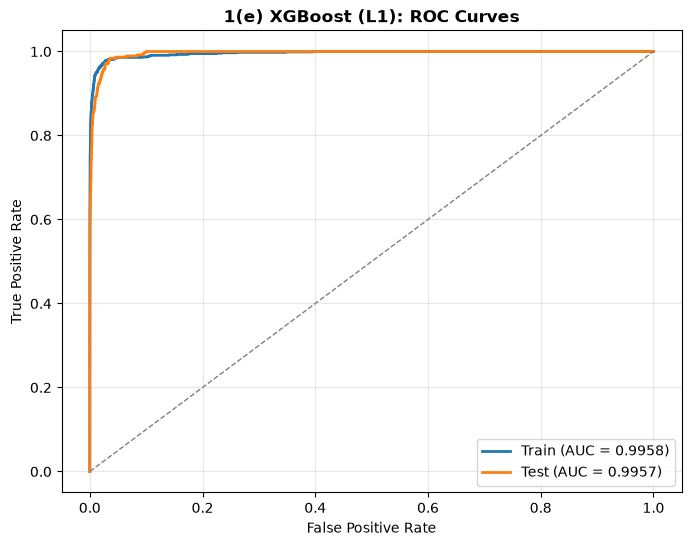

5-fold CV misclassification estimate: 0.00787 (std 0.00055)
Test misclassification rate:          0.00906


In [11]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_base = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4,
                         tree_method="hist", eval_metric="logloss",
                         random_state=42, n_jobs=1)

alpha_grid = [0, 0.01, 0.1, 1, 10, 100]

# Select alpha by CV AUC; also record CV accuracy for the error estimate
grid_search = GridSearchCV(xgb_base, {"reg_alpha": alpha_grid},
                           cv=cv_strat,
                           scoring={"auc": "roc_auc", "acc": "accuracy"},
                           refit="auc", n_jobs=-1)
grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_["reg_alpha"]
best_xgb = grid_search.best_estimator_
cv_res = grid_search.cv_results_
best_i = grid_search.best_index_

print("=" * 60)
print("1(e): XGBOOST WITH L1 PENALTY (NO COMPENSATION)")
print("=" * 60)
print("5-fold CV results for each alpha:")
for a, auc_m, acc_m in zip(alpha_grid, cv_res["mean_test_auc"],
                           cv_res["mean_test_acc"]):
    print(f"  alpha = {a:<6} CV AUC = {auc_m:.5f}   "
          f"CV error = {1 - acc_m:.5f}")
print(f"\nSelected alpha (reg_alpha): {best_alpha}\n")

xgb_results = evaluate_classifier(best_xgb, "1(e) XGBoost (L1)")

cv_error = 1 - cv_res["mean_test_acc"][best_i]
print(f"5-fold CV misclassification estimate: {cv_error:.5f} "
      f"(std {cv_res['std_test_acc'][best_i]:.5f})")
print(f"Test misclassification rate:          "
      f"{xgb_results['Test']['misclassification']:.5f}")

**Result (1(e)):**

**Choice of $\alpha$:** cross-validated AUC is almost flat for $\alpha$ between 0 and 10 (0.98804 to 0.98937), peaks at **$\alpha$ = 10**, and drops at $\alpha$ = 100 (0.98220), where the penalty shrinks the leaf weights too much. We selected $\alpha$ by AUC rather than accuracy because of the imbalance; by CV error alone, $\alpha$ = 1 would be marginally better (0.00637 vs. 0.00787), so the choice of selection criterion matters slightly here.

| | Misclassification | AUC | Recall (pos) | Precision (pos) |
|---|---|---|---|---|
| Training set | 0.00457 | 0.99578 | 0.78700 | 0.92807 |
| Test set | **0.00906** | **0.99573** | 0.69067 | 0.89931 |

* **CV vs. test error:** the 5-fold CV estimate of the misclassification error (0.00787, std 0.00055) is somewhat lower than the test error (0.00906). As in 1(c), the test set contains a larger share of positives (2.34% vs. 1.67%), and most errors are missed positives, so a higher test error is expected. The CV estimate is a reasonable, slightly optimistic guide to the test error.
* **No overfitting:** unlike the random forest, XGBoost does not memorize the training data. Training and test AUC are almost identical (0.9958 vs. 0.9957), because the trees are shallow (depth 4) and the $L_1$ penalty shrinks the leaf weights.
* **The imbalance still hurts recall:** XGBoost misses **116 of the 375** test failures (recall 0.691), similar to the uncompensated random forest in 1(c) (106 missed, recall 0.717). Without compensation, the loss function is dominated by the 59,000 negatives.
* **Compared with the random forest (1(c)):** XGBoost has the highest test AUC so far (0.9957 vs. 0.9928), so it ranks trucks by failure risk slightly better, but at the default 0.5 threshold its misclassification (0.00906 vs. 0.00756) and recall (0.691 vs. 0.717) are slightly worse. As with the random forest, the main problem is the threshold, not the ranking, which is what SMOTE in 1(f) addresses.

### 1(f). XGBoost with SMOTE

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new synthetic minority-class examples by interpolating between each positive training instance and one of its k nearest positive neighbors, until the two classes are the same size. We train the same $L_1$-penalized XGBoost model as in 1(e) on SMOTE-balanced data and repeat every output of 1(e).

**Right vs. wrong way to cross-validate:**
* **Wrong:** apply SMOTE to the whole training set and then cross-validate. The synthetic positives are built from real positives that end up in the validation folds, so information leaks from validation into training, and the validation folds also contain synthetic points. The CV estimate becomes overly optimistic.
* **Right (used here):** put SMOTE inside an `imblearn` `Pipeline`, so in each CV split SMOTE is fit **only on the training folds**, and the model is validated on real, untouched data. The test set is never oversampled.

1(f): XGBOOST WITH L1 PENALTY + SMOTE
5-fold CV results for each alpha (SMOTE inside each fold):
  alpha = 0      CV AUC = 0.98493   CV error = 0.01480
  alpha = 0.01   CV AUC = 0.98489   CV error = 0.01470
  alpha = 0.1    CV AUC = 0.98517   CV error = 0.01493
  alpha = 1      CV AUC = 0.98420   CV error = 0.01510
  alpha = 10     CV AUC = 0.98467   CV error = 0.01563
  alpha = 100    CV AUC = 0.98405   CV error = 0.02098

Selected alpha (reg_alpha): 0.1

--- Train set ---


,Pred neg,Pred pos
Actual neg,58302,698
Actual pos,62,938


  misclassification  0.01267
  AUC                0.99681
  recall (pos)       0.93800
  precision (pos)    0.57335

--- Test set ---


,Pred neg,Pred pos
Actual neg,15383,242
Actual pos,32,343


  misclassification  0.01713
  AUC                0.99376
  recall (pos)       0.91467
  precision (pos)    0.58632



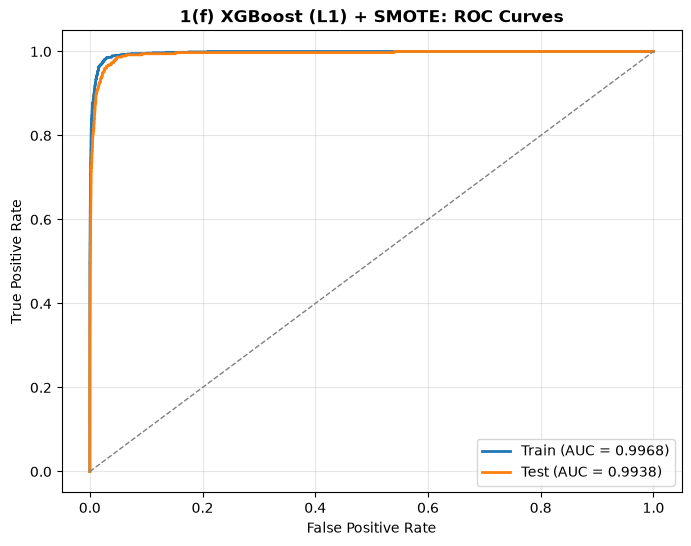

5-fold CV misclassification estimate: 0.01493 (std 0.00127)
Test misclassification rate:          0.01713

Comparison with 1(e):


,alpha,CV error,Test misclassification,Test AUC,Test recall (pos),Test precision (pos)
Model,,,,,,
"1(e) XGBoost, uncompensated",10.0,0.00787,0.00906,0.99573,0.69067,0.89931
1(f) XGBoost + SMOTE,0.1,0.01493,0.01713,0.99376,0.91467,0.58632


In [12]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# SMOTE inside the pipeline: applied to the training folds only
smote_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4,
                          tree_method="hist", eval_metric="logloss",
                          random_state=42, n_jobs=1))
])

grid_search_smote = GridSearchCV(
    smote_pipeline, {"xgb__reg_alpha": alpha_grid}, cv=cv_strat,
    scoring={"auc": "roc_auc", "acc": "accuracy"}, refit="auc",
    n_jobs=-1)
grid_search_smote.fit(X_train, y_train)

best_alpha_smote = grid_search_smote.best_params_["xgb__reg_alpha"]
best_smote = grid_search_smote.best_estimator_
cv_res_s = grid_search_smote.cv_results_
best_i_s = grid_search_smote.best_index_

print("=" * 60)
print("1(f): XGBOOST WITH L1 PENALTY + SMOTE")
print("=" * 60)
print("5-fold CV results for each alpha (SMOTE inside each fold):")
for a, auc_m, acc_m in zip(alpha_grid, cv_res_s["mean_test_auc"],
                           cv_res_s["mean_test_acc"]):
    print(f"  alpha = {a:<6} CV AUC = {auc_m:.5f}   "
          f"CV error = {1 - acc_m:.5f}")
print(f"\nSelected alpha (reg_alpha): {best_alpha_smote}\n")

smote_results = evaluate_classifier(best_smote, "1(f) XGBoost (L1) + SMOTE")

cv_error_smote = 1 - cv_res_s["mean_test_acc"][best_i_s]
print(f"5-fold CV misclassification estimate: {cv_error_smote:.5f} "
      f"(std {cv_res_s['std_test_acc'][best_i_s]:.5f})")
print(f"Test misclassification rate:          "
      f"{smote_results['Test']['misclassification']:.5f}")

# Uncompensated (1(e)) vs. SMOTE (1(f))
rows = []
for label, res, cv_err, a in [
        ("1(e) XGBoost, uncompensated", xgb_results, cv_error, best_alpha),
        ("1(f) XGBoost + SMOTE", smote_results, cv_error_smote,
         best_alpha_smote)]:
    rows.append({"Model": label, "alpha": a,
                 "CV error": cv_err,
                 "Test misclassification": res["Test"]["misclassification"],
                 "Test AUC": res["Test"]["AUC"],
                 "Test recall (pos)": res["Test"]["recall (pos)"],
                 "Test precision (pos)": res["Test"]["precision (pos)"]})
print("\nComparison with 1(e):")
display(pd.DataFrame(rows).set_index("Model").round(5))

**Result (1(f)):**

**Choice of $\alpha$:** with SMOTE inside each fold, CV AUC is nearly flat for $\alpha$ from 0 to 10 (0.98420 to 0.98517) and is highest at **$\alpha$ = 0.1**. CV error rises at $\alpha$ = 100 (0.02098), where the penalty is too strong.

| Model | $\alpha$ | CV error | Test misclassification | Test AUC | Test recall (pos) | Test precision (pos) |
|---|---|---|---|---|---|---|
| 1(e) XGBoost, uncompensated | 10 | 0.00787 | 0.00906 | 0.99573 | 0.69067 | 0.89931 |
| 1(f) XGBoost + SMOTE | 0.1 | 0.01493 | 0.01713 | 0.99376 | **0.91467** | 0.58632 |

Training set (SMOTE model, evaluated on the original training data): misclassification 0.01267, AUC 0.99681, recall 0.938, precision 0.573.

* **SMOTE greatly improves detection of failures.** Missed APS failures on the test set drop from **116 to 32 of 375** (recall 0.691 to 0.915). Training on balanced data shifts the model toward predicting `pos`, so many more failures are caught.
* **The cost is more false alarms.** False positives rise from 29 to 242 of the 15,625 healthy trucks (precision 0.899 to 0.586), so the overall misclassification rate roughly doubles (0.00906 to 0.01713). As in 1(d), compensating for imbalance trades precision for recall.
* **AUC is essentially unchanged** (0.9957 vs. 0.9938): SMOTE does not make the model better at ranking trucks by risk; it mainly moves the decision boundary toward the minority class.
* **CV vs. test error:** the CV estimate (0.01493, std 0.00127) is close to, and slightly below, the test error (0.01713), consistent with the test set's larger share of positives. Because SMOTE was applied only within the training folds, each fold was validated on real data, so this estimate is realistic. Applying SMOTE before cross-validation would have produced an overly optimistic estimate.
* **Comparison with the balanced random forest (1(d)):** the balanced random forest has the highest recall (0.984, 6 missed failures) but many more false alarms (836, precision 0.306). XGBoost with SMOTE sits between the uncompensated models and the balanced forest: it misses more failures (32) but raises far fewer false alarms (242).

**Conclusion:** compensating for class imbalance, whether by undersampling (1(d)) or SMOTE (1(f)), is essential when missed failures are costly, since the uncompensated models miss over a quarter of APS failures. The best choice among the compensated models depends on the relative cost of a missed failure versus an unnecessary inspection.

## 2. ISLR 6.6.3 (Lasso with Constraint $s$)

The lasso estimates are found by

$$\underset{\beta}{\text{minimize}} \sum_{i=1}^{n}\Big(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\Big)^2 \quad \text{subject to} \quad \sum_{j=1}^{p}|\beta_j| \le s.$$

We consider what happens as $s$ increases from 0.

**(a) Training RSS: iv. Steadily decrease.**
When $s = 0$, all $\beta_j = 0$ and the model predicts only the intercept, so the training RSS is at its largest. Increasing $s$ only enlarges the set of allowed coefficients, so the minimum training RSS can never go up. It steadily decreases until $s$ is large enough to include the least squares solution, after which it stays at the least squares RSS.

**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape.**
For small $s$, the model is too restricted and underfits (high bias), so the test RSS is high. As $s$ grows, the model captures the real relationships and the test RSS falls. Past some point, the extra flexibility mainly fits noise in the training data (high variance), and the test RSS rises again.

**(c) Variance: iii. Steadily increase.**
When $s = 0$, the coefficients are fixed at 0 regardless of the data, so the variance is 0. As $s$ increases, the coefficients are free to follow the particular training sample more closely, so the variance of the fitted model steadily increases.

**(d) Squared bias: iv. Steadily decrease.**
When $s = 0$, the model is far too simple, so the squared bias is large. As $s$ increases, the model becomes more flexible and can approximate the true relationship more closely, so the squared bias steadily decreases.

**(e) Irreducible error: v. Remain constant.**
The irreducible error $\text{Var}(\epsilon)$ is the noise in the response itself. It does not depend on the model, so changing $s$ has no effect on it.

## 3. ISLR 6.6.5 (Ridge vs. Lasso with Identical Predictors)

We have $n = 2$, $p = 2$, with $x_{11} = x_{12} = x_1$ and $x_{21} = x_{22} = x_2$. Since $x_1 + x_2 = 0$ and $y_1 + y_2 = 0$, the intercept estimate is 0, and $x_2 = -x_1$, $y_2 = -y_1$.

**(a) Ridge regression optimization problem**

$$\underset{\beta_1, \beta_2}{\text{minimize}} \; (y_1 - \beta_1 x_1 - \beta_2 x_1)^2 + (y_2 - \beta_1 x_2 - \beta_2 x_2)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

Substituting $x_2 = -x_1$ and $y_2 = -y_1$, the second squared term becomes $\big(-y_1 + x_1(\beta_1 + \beta_2)\big)^2 = \big(y_1 - x_1(\beta_1 + \beta_2)\big)^2$, so the objective is

$$L(\beta_1, \beta_2) = 2\big(y_1 - x_1(\beta_1 + \beta_2)\big)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b) The ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$**

Setting the partial derivatives to zero:

$$\frac{\partial L}{\partial \beta_1} = -4x_1\big(y_1 - x_1(\beta_1 + \beta_2)\big) + 2\lambda\beta_1 = 0,$$

$$\frac{\partial L}{\partial \beta_2} = -4x_1\big(y_1 - x_1(\beta_1 + \beta_2)\big) + 2\lambda\beta_2 = 0.$$

Subtracting the two equations gives $2\lambda\beta_1 = 2\lambda\beta_2$. Since $\lambda > 0$, this means $\hat\beta_1 = \hat\beta_2$. (The objective is strictly convex for $\lambda > 0$, so this solution is unique.)

**(c) Lasso optimization problem**

With the same simplifications as in (a), the lasso minimizes

$$2\big(y_1 - x_1(\beta_1 + \beta_2)\big)^2 + \lambda\big(|\beta_1| + |\beta_2|\big).$$

**(d) The lasso coefficients are not unique**

Let $t = \beta_1 + \beta_2$. The squared-error term depends only on $t$, and by the triangle inequality $|\beta_1| + |\beta_2| \ge |t|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one of them is 0). So for any fixed $t$, the objective takes its smallest value, $2(y_1 - x_1 t)^2 + \lambda|t|$, at every pair with $\beta_1 + \beta_2 = t$ and $\beta_1, \beta_2$ of the same sign. Minimizing over $t$ gives one optimal value $\hat t$, but every pair

$$\hat\beta_1 + \hat\beta_2 = \hat t, \qquad \hat\beta_1, \hat\beta_2 \text{ with the same sign as } \hat t$$

is a solution: a whole line segment of solutions rather than a single point.

**Geometric view:** in the constrained form, the RSS contours are the lines $\beta_1 + \beta_2 = \text{constant}$, which are parallel to an edge of the diamond $|\beta_1| + |\beta_2| \le s$. The contours therefore touch the diamond along an entire edge rather than at a single corner, so the lasso solution is not unique. In contrast, the circular ridge constraint touches the contours at a single point, which gives the unique solution $\hat\beta_1 = \hat\beta_2$ from (b).

## 4. ISLR 8.4.5 (Majority Vote vs. Average Probability)

Ten bootstrapped trees give the following estimates of $P(\text{Class is Red} \mid X)$:

$$0.1,\ 0.15,\ 0.2,\ 0.2,\ 0.55,\ 0.6,\ 0.6,\ 0.65,\ 0.7,\ 0.75.$$

**Approach 1: Majority vote**

Each tree votes Red if its probability is above 0.5:
* Red votes: 0.55, 0.6, 0.6, 0.65, 0.7, 0.75 (**6 trees**)
* Green votes: 0.1, 0.15, 0.2, 0.2 (**4 trees**)

Since 6 of the 10 trees vote Red, the majority vote classification is **Red**.

**Approach 2: Average probability**

$$\bar{P} = \frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.5}{10} = \mathbf{0.45}.$$

Since $0.45 < 0.5$, the average probability classification is **Green**.

**Why they disagree:** majority vote only counts which side of 0.5 each tree is on and ignores how confident it is. The six Red votes are only moderately confident (0.55 to 0.75), while the four Green votes are very confident (0.1 to 0.2), and those four pull the average below 0.5.

## 5. ISLR 9.7.3 (Maximal Margin Classifier)

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

The sketches for (a), (b), (d), (e) and (g) are in the figure below.

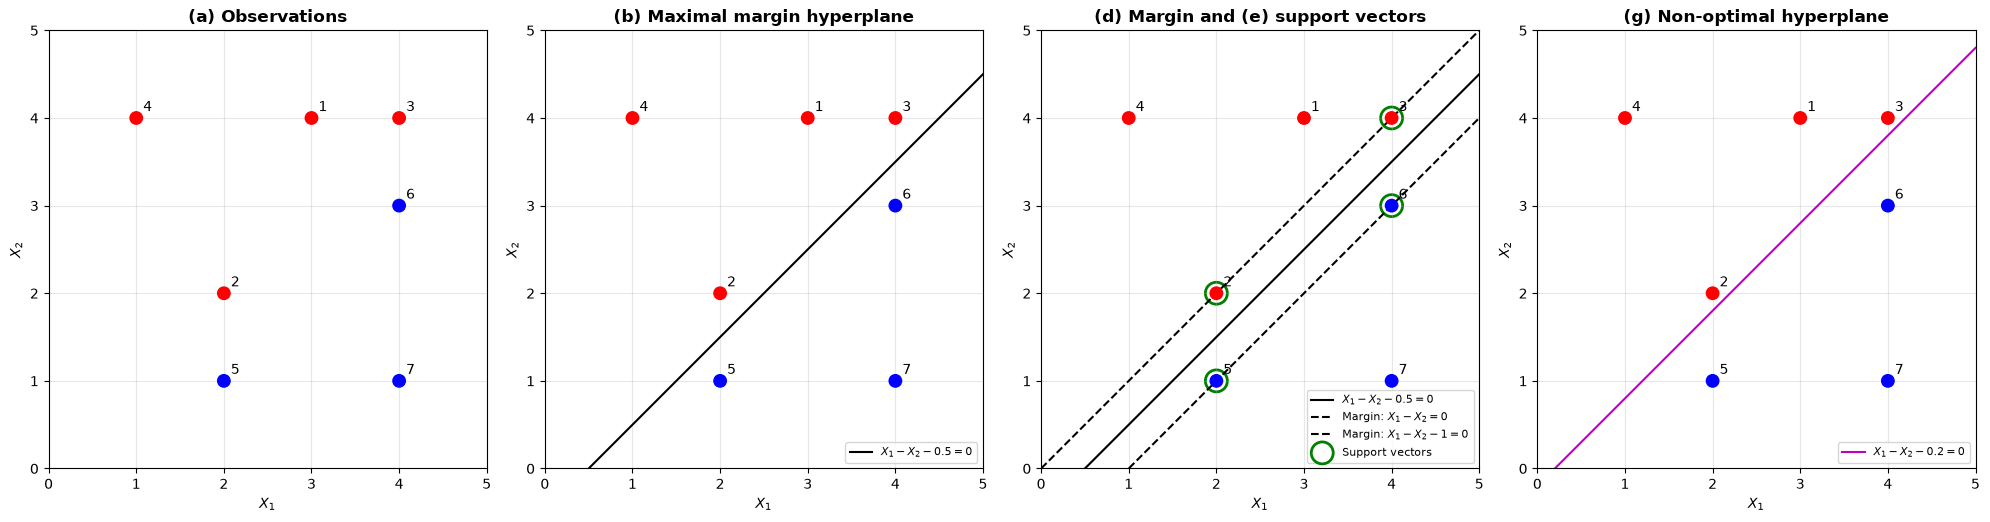

In [13]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
colors = ["red"] * 4 + ["blue"] * 3
xs = np.linspace(0, 5, 100)

fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=100)
titles = ["(a) Observations", "(b) Maximal margin hyperplane",
          "(d) Margin and (e) support vectors",
          "(g) Non-optimal hyperplane"]

for ax, title in zip(axes, titles):
    ax.scatter(X[:, 0], X[:, 1], c=colors, s=80, zorder=3)
    for i, (x1, x2) in enumerate(X, 1):
        ax.annotate(str(i), (x1, x2), xytext=(5, 5),
                    textcoords="offset points")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_title(title, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal")

# (b) hyperplane X2 = X1 - 0.5
for ax in axes[1:3]:
    ax.plot(xs, xs - 0.5, "k-", label="$X_1 - X_2 - 0.5 = 0$")

# (d) margins and (e) support vectors
axes[2].plot(xs, xs, "k--", label="Margin: $X_1 - X_2 = 0$")
axes[2].plot(xs, xs - 1, "k--", label="Margin: $X_1 - X_2 - 1 = 0$")
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
axes[2].scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none",
                edgecolors="green", linewidths=2, label="Support vectors")

# (g) a separating but non-optimal hyperplane
axes[3].plot(xs, xs - 0.2, "m-", label="$X_1 - X_2 - 0.2 = 0$")

for ax in axes[1:]:
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(a) Sketch of the observations.** See the first panel. The Red observations lie above and to the left of the Blue ones.

**(b) Optimal separating hyperplane.**
The closest pairs of opposite-class points are (2, 2) Red with (2, 1) Blue, and (4, 4) Red with (4, 3) Blue. The maximal margin hyperplane passes halfway between them, through (2, 1.5) and (4, 3.5):
* Slope: $\frac{3.5 - 1.5}{4 - 2} = 1$
* Intercept: $1.5 = 1 \cdot 2 + b \Rightarrow b = -0.5$, so $X_2 = X_1 - 0.5$

In the form $\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$: $\mathbf{0.5 - X_1 + X_2 = 0}$, i.e. $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(c) Classification rule.**
Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise.

**(d) Margin.** See the third panel. The margin lines are parallel to the hyperplane and pass through the closest points of each class:
* Red side: $X_1 - X_2 = 0$, through (2, 2) and (4, 4)
* Blue side: $X_1 - X_2 - 1 = 0$, through (2, 1) and (4, 3)

The margin is $M = \frac{0.5}{\sqrt{1^2 + (-1)^2}} = \frac{0.5}{\sqrt{2}} \approx \mathbf{0.354}$, the distance from the hyperplane to each margin line. The total width between the two margin lines is $\frac{1}{\sqrt{2}} \approx 0.707$.

**(e) Support vectors.** The points that lie on the margin lines (circled in green):
* Red: observations 2 (2, 2) and 3 (4, 4)
* Blue: observations 5 (2, 1) and 6 (4, 3)

**(f) Moving observation 7.**
Observation 7, (4, 1), is not a support vector: it lies well outside the margin. The maximal margin hyperplane depends only on the support vectors, so a slight movement of observation 7 has **no effect** on the hyperplane, as long as it does not move inside the margin.

**(g) A non-optimal separating hyperplane.** See the fourth panel:
$$\mathbf{0.2 - X_1 + X_2 = 0} \quad (X_2 = X_1 - 0.2).$$
It still separates the classes (every Red point gives a positive value and every Blue point a negative one), but it sits much closer to the Red points (distance $\frac{0.2}{\sqrt{2}} \approx 0.141$ from (2, 2) and (4, 4)) than to the Blue points ($\frac{0.8}{\sqrt{2}} \approx 0.566$), so it is not the maximal margin hyperplane.

**(h) Making the classes non-separable.**
Add an eighth observation at $(3, 1)$ with class **Red**. This point lies on the segment between the Blue observations 5 (2, 1) and 7 (4, 1), so any line that puts both of those Blue points on one side must also put (3, 1) on that side. No hyperplane can separate the two classes anymore.